# Section A — Dataset & EDA

## A1 — Dataset Loading & Audit

In [1]:
# Import required libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv("../data/airline_passenger_satisfaction.csv")

# Display dataset shape
print("Dataset Shape:", df.shape)

# Display data types
print("\nData Types:")
print(df.dtypes)

# Display missing-value counts
print("\nMissing Values:")
print(df.isnull().sum())

# Display target/class distribution
print("\nTarget Distribution:")
print(df["Satisfaction"].value_counts())

Dataset Shape: (129880, 24)

Data Types:
ID                                          int64
Gender                                        str
Age                                         int64
Customer Type                                 str
Type of Travel                                str
Class                                         str
Flight Distance                             int64
Departure Delay                             int64
Arrival Delay                             float64
Departure and Arrival Time Convenience      int64
Ease of Online Booking                      int64
Check-in Service                            int64
Online Boarding                             int64
Gate Location                               int64
On-board Service                            int64
Seat Comfort                                int64
Leg Room Service                            int64
Cleanliness                                 int64
Food and Drink                              int64
In-flight

## A2 — EDA Visualisations

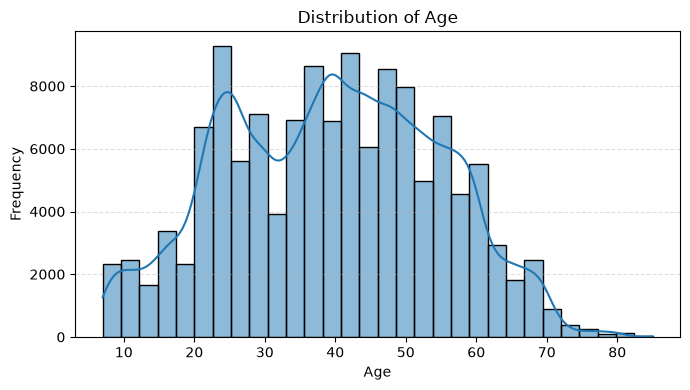

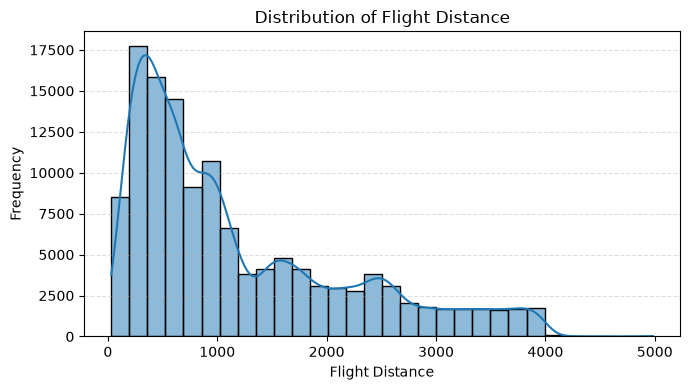

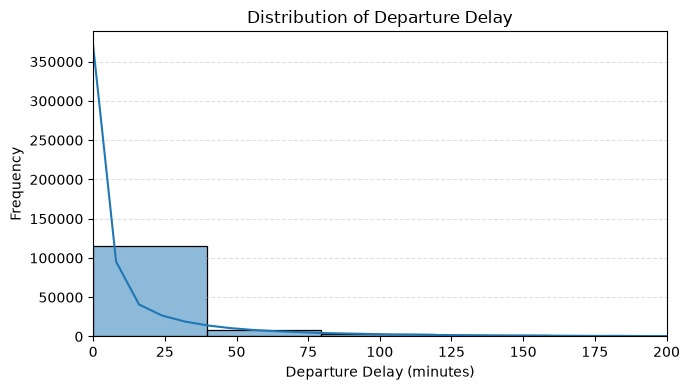

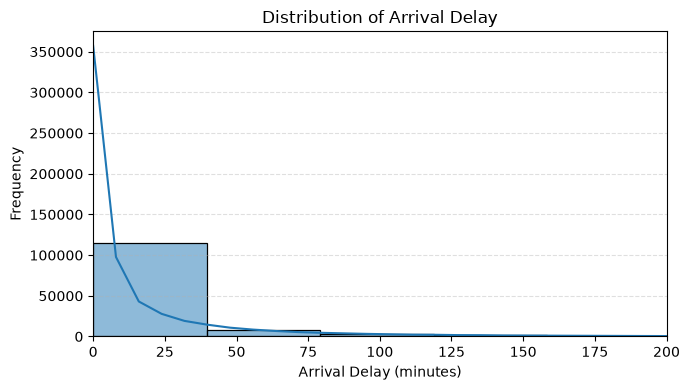

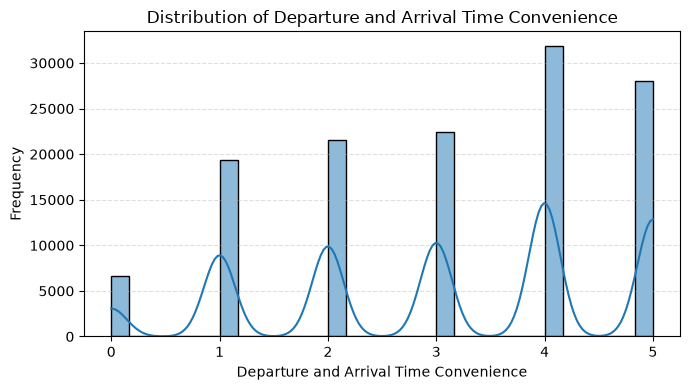

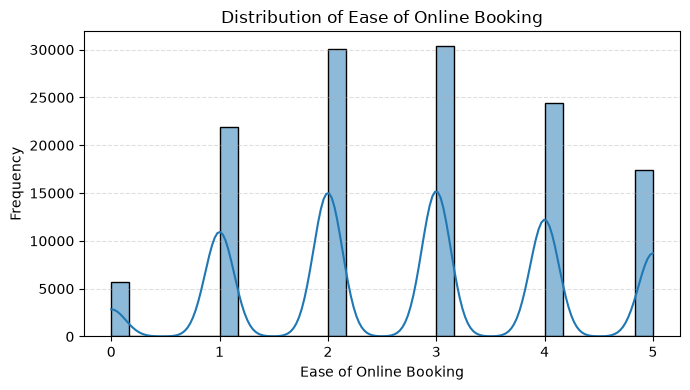

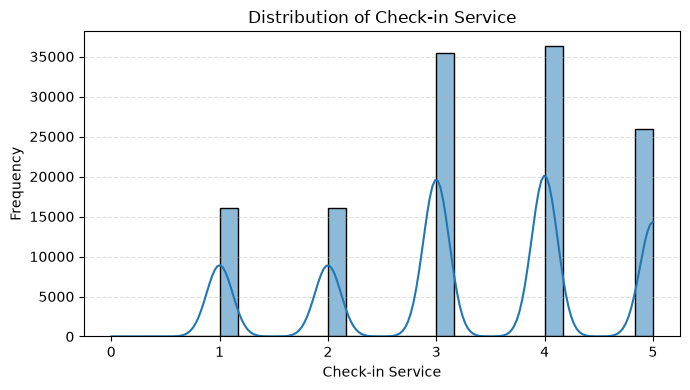

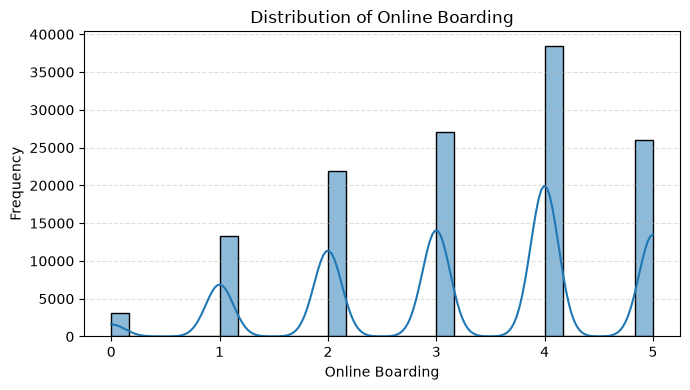

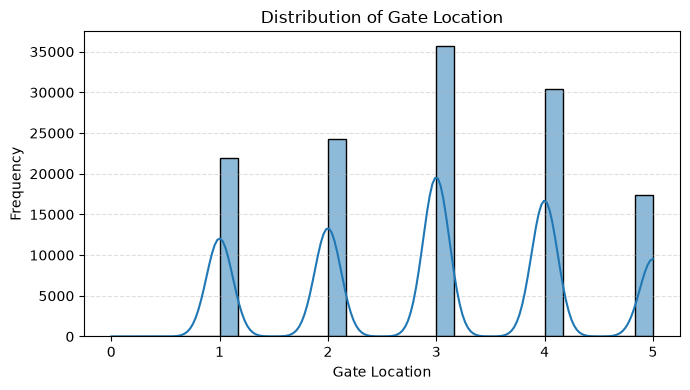

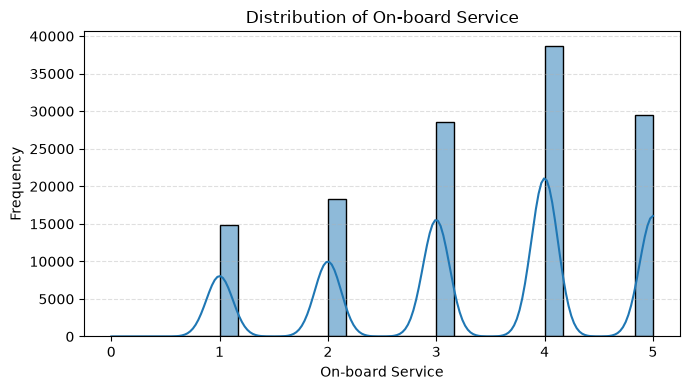

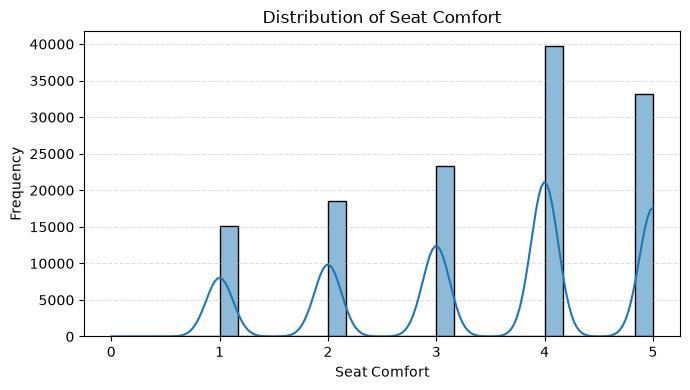

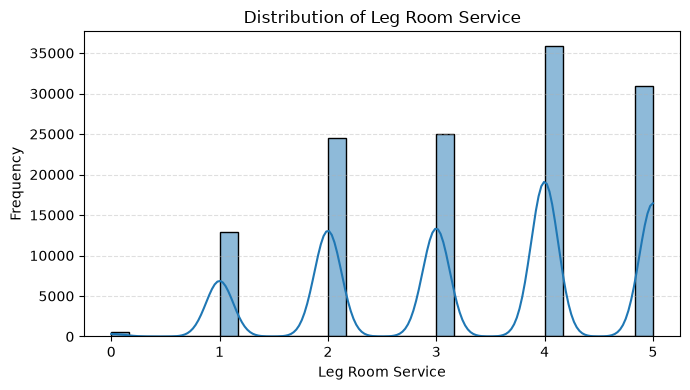

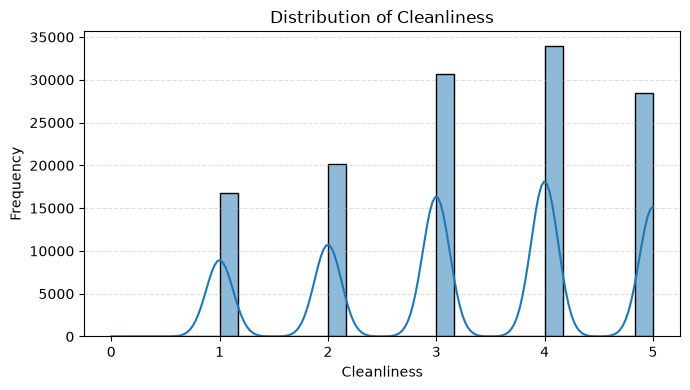

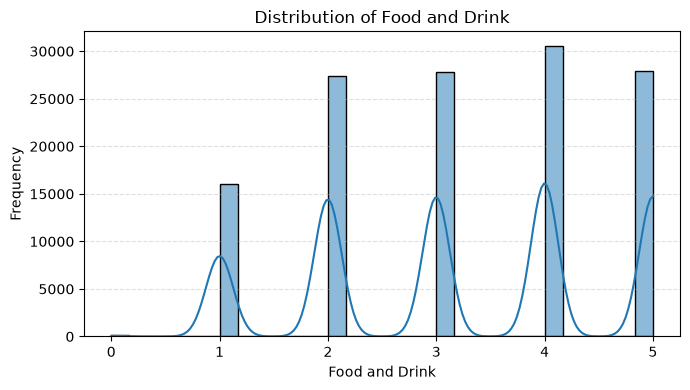

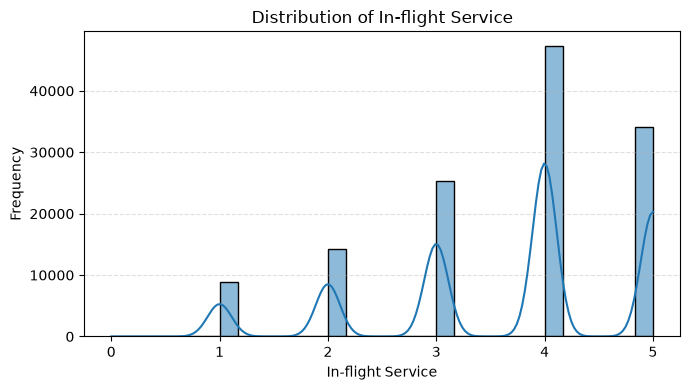

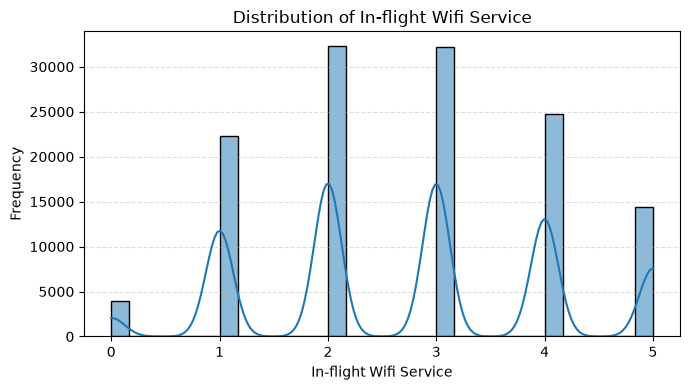

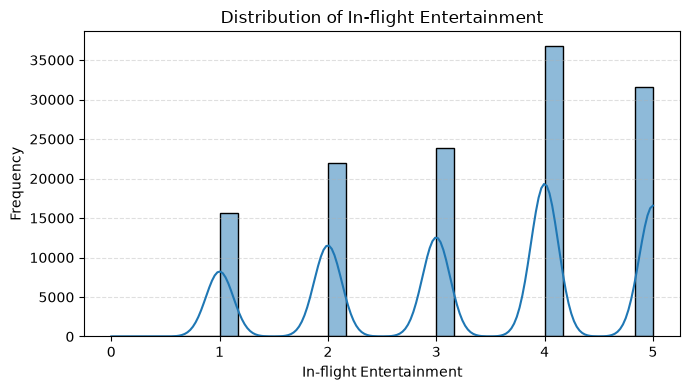

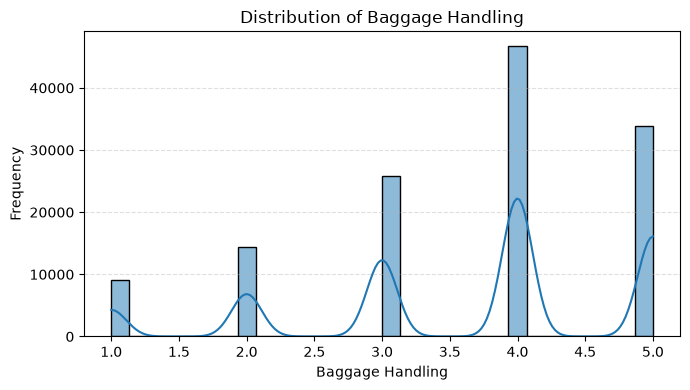

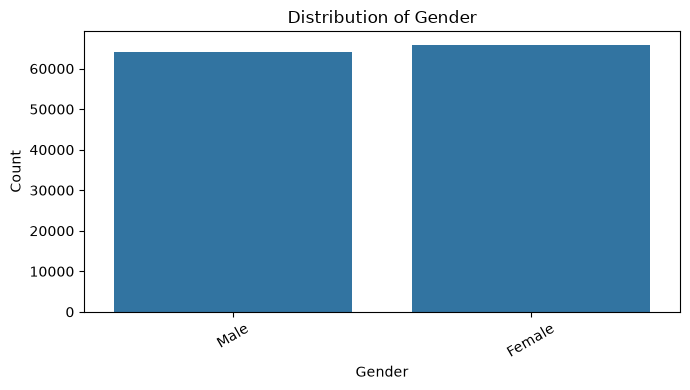

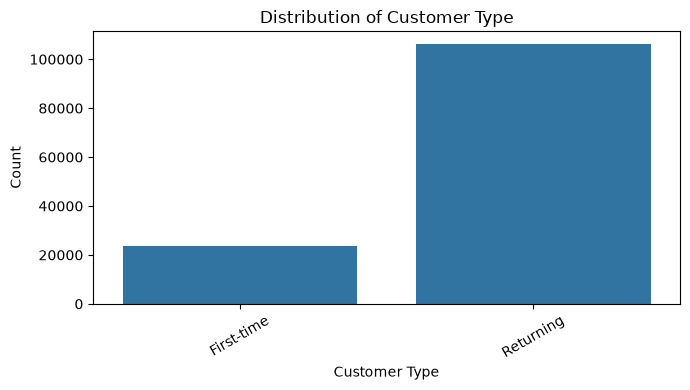

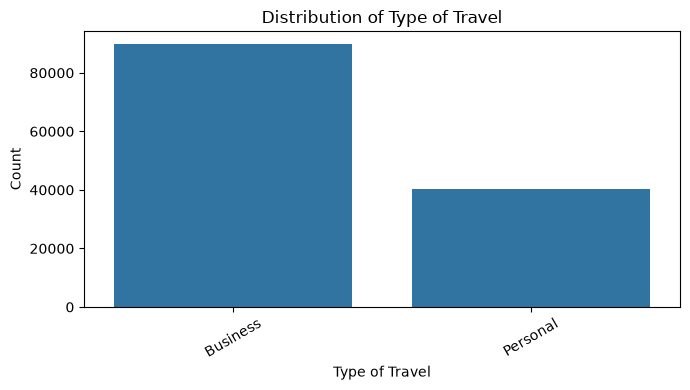

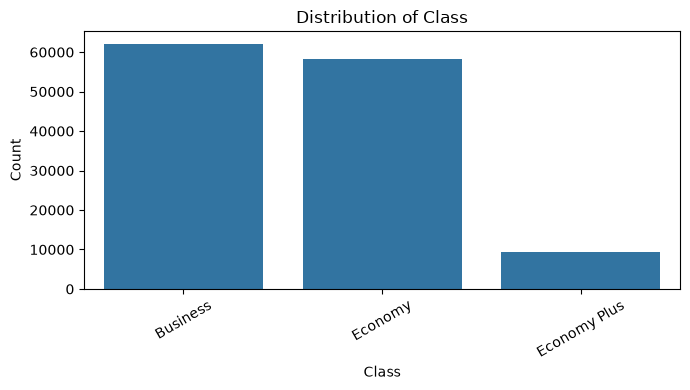

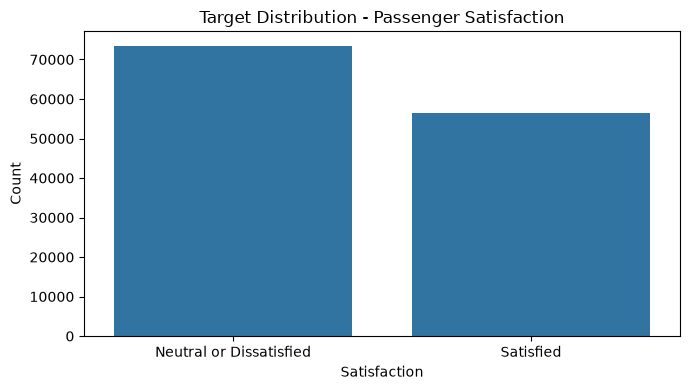

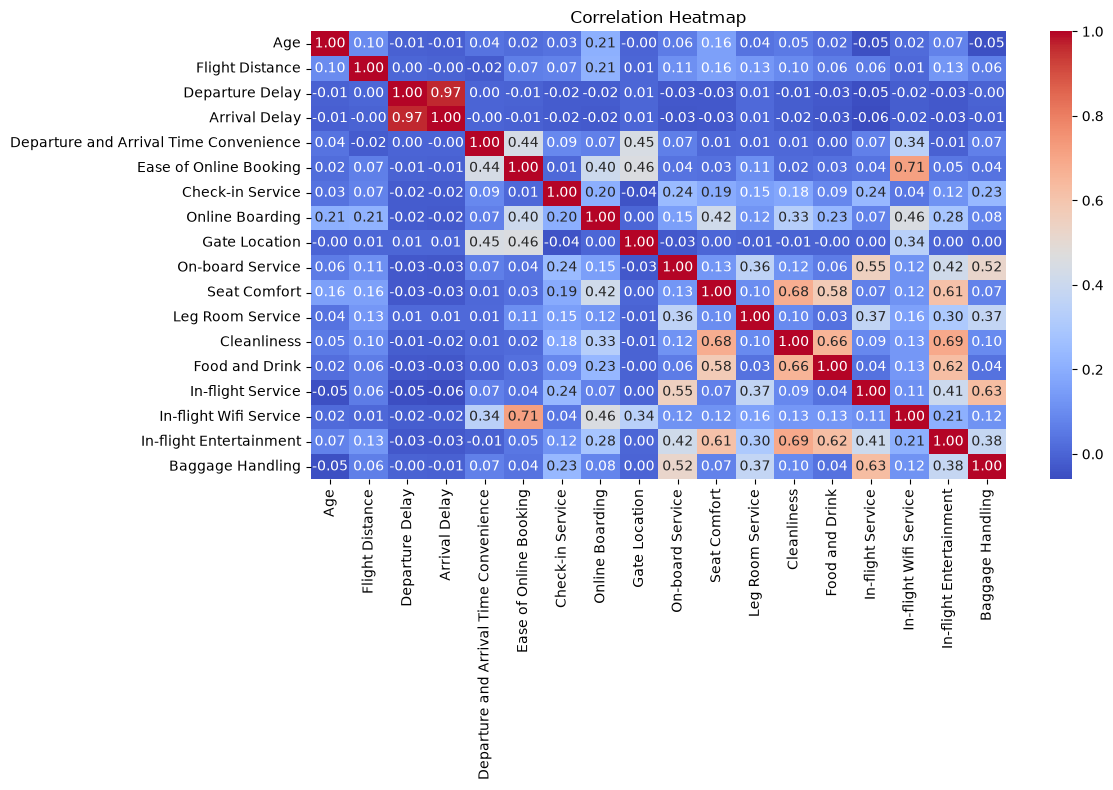

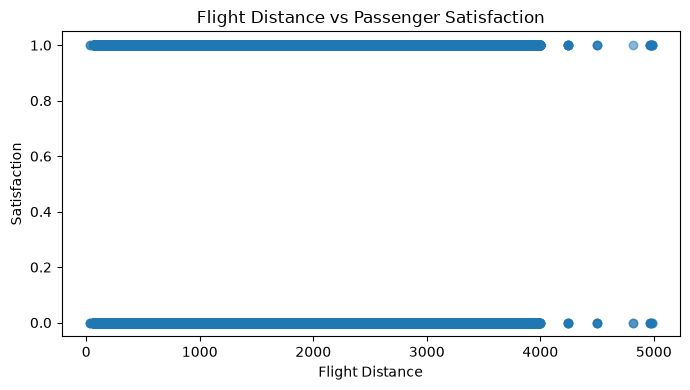

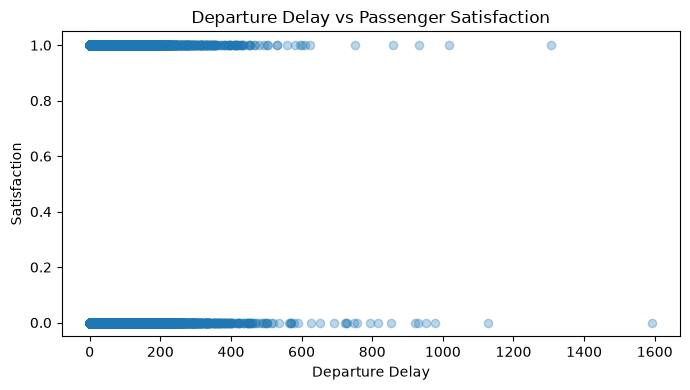

In [2]:
# Separate numerical and categorical features
numerical_features = df.select_dtypes(include=["int64", "float64"]).columns.tolist()

# Remove ID because it is an identifier, not a meaningful numerical feature
if "ID" in numerical_features:
    numerical_features.remove("ID")

# Explicitly select string/categorical features
categorical_features = df.select_dtypes(include=["str"]).columns.tolist()


# --------------------------------------------------
# Distribution plots for numerical features
# --------------------------------------------------

for column in numerical_features:

    plt.figure(figsize=(7, 4))

    # For delay variables, zoom into the main distribution
    if column in ["Departure Delay", "Arrival Delay"]:

        sns.histplot(
            df[column].dropna(),
            bins=40,
            kde=True
        )

        plt.xlim(0, 200)

        plt.title(f"Distribution of {column}")
        plt.xlabel(f"{column} (minutes)")
        plt.ylabel("Frequency")

    else:

        sns.histplot(
            df[column].dropna(),
            bins=30,
            kde=True
        )

        plt.title(f"Distribution of {column}")
        plt.xlabel(column)
        plt.ylabel("Frequency")

    plt.grid(
        axis="y",
        linestyle="--",
        alpha=0.4
    )

    plt.tight_layout()
    plt.show()


# --------------------------------------------------
# Distribution plots for categorical features
# --------------------------------------------------

for column in categorical_features:
    if column != "Satisfaction":
        plt.figure(figsize=(7, 4))
        sns.countplot(data=df, x=column)
        plt.title(f"Distribution of {column}")
        plt.xlabel(column)
        plt.ylabel("Count")
        plt.xticks(rotation=30)
        plt.tight_layout()
        plt.show()


# --------------------------------------------------
# Target distribution
# --------------------------------------------------

plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="Satisfaction")
plt.title("Target Distribution - Passenger Satisfaction")
plt.xlabel("Satisfaction")
plt.ylabel("Count")
plt.tight_layout()
plt.show()


# --------------------------------------------------
# Correlation heatmap
# --------------------------------------------------

plt.figure(figsize=(12, 8))
sns.heatmap(
    df[numerical_features].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()


# --------------------------------------------------
# Scatter plot 1: Flight Distance vs Satisfaction
# --------------------------------------------------

satisfaction_numeric = df["Satisfaction"].map({
    "Neutral or Dissatisfied": 0,
    "Satisfied": 1
})

plt.figure(figsize=(7, 4))
plt.scatter(
    df["Flight Distance"],
    satisfaction_numeric,
    alpha=0.3
)
plt.title("Flight Distance vs Passenger Satisfaction")
plt.xlabel("Flight Distance")
plt.ylabel("Satisfaction")
plt.tight_layout()
plt.show()


# --------------------------------------------------
# Scatter plot 2: Departure Delay vs Satisfaction
# --------------------------------------------------

plt.figure(figsize=(7, 4))
plt.scatter(
    df["Departure Delay"],
    satisfaction_numeric,
    alpha=0.3
)
plt.title("Departure Delay vs Passenger Satisfaction")
plt.xlabel("Departure Delay")
plt.ylabel("Satisfaction")
plt.tight_layout()
plt.show()

## A3 — Insight Commentary

### Observations

- **Feature distributions:** The distribution plots show the spread and frequency of the numerical and categorical features in the dataset.

- **Target distribution:** The target distribution shows the number of passengers belonging to the Satisfied and Neutral or Dissatisfied classes.

- **Correlation heatmap:** The heatmap shows the relationships between the numerical features and helps identify features with relatively stronger correlations.

- **Flight Distance vs Satisfaction:** The scatter plot shows how the two satisfaction classes are distributed across different flight distances.

- **Departure Delay vs Satisfaction:** The scatter plot shows how passenger satisfaction is distributed across different departure delay values.

# Section B — Preprocessing & Feature Engineering

## B1 — Data Cleaning

In [3]:
# ============================================================
# B1 — DATA CLEANING
# ============================================================

# Make a copy of the dataset before preprocessing
data = df.copy()

# ------------------------------------------------------------
# Remove duplicate rows
# ------------------------------------------------------------

print("Duplicate rows before removal:", data.duplicated().sum())

data = data.drop_duplicates()

print("Duplicate rows after removal:", data.duplicated().sum())


# ------------------------------------------------------------
# Remove ID column
# ------------------------------------------------------------

# ID is only an identifier and does not provide useful
# predictive information for passenger satisfaction

data = data.drop(columns=["ID"])


# ------------------------------------------------------------
# Handle missing values
# ------------------------------------------------------------

print("\nMissing values before treatment:")
print(data.isnull().sum()[data.isnull().sum() > 0])

# Fill missing Arrival Delay values with the median
# Median is less affected by extreme delay values

data["Arrival Delay"] = data["Arrival Delay"].fillna(
    data["Arrival Delay"].median()
)

print("\nMissing values after treatment:")
print(data.isnull().sum()[data.isnull().sum() > 0])


# ------------------------------------------------------------
# Check numerical outliers
# ------------------------------------------------------------

numerical_columns = data.select_dtypes(
    include=["int64", "float64"]
).columns

print("\nOutlier counts using the IQR method:")

for column in numerical_columns:

    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = (
        (data[column] < lower_bound) |
        (data[column] > upper_bound)
    ).sum()

    print(f"{column}: {outliers}")

Duplicate rows before removal: 0
Duplicate rows after removal: 0

Missing values before treatment:
Arrival Delay    393
dtype: int64

Missing values after treatment:
Series([], dtype: int64)

Outlier counts using the IQR method:
Age: 0
Flight Distance: 2855
Departure Delay: 18098
Arrival Delay: 17492
Departure and Arrival Time Convenience: 0
Ease of Online Booking: 0
Check-in Service: 16109
Online Boarding: 0
Gate Location: 0
On-board Service: 0
Seat Comfort: 0
Leg Room Service: 0
Cleanliness: 0
Food and Drink: 0
In-flight Service: 0
In-flight Wifi Service: 0
In-flight Entertainment: 0
Baggage Handling: 0


## B2 — Encoding, Scaling & Splitting

In [4]:
# ============================================================
# B2 — ENCODING, SCALING & SPLITTING
# ============================================================

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer


# ------------------------------------------------------------
# Separate features and target
# ------------------------------------------------------------

X = data.drop(columns=["Satisfaction"])

y = data["Satisfaction"].map({
    "Neutral or Dissatisfied": 0,
    "Satisfied": 1
})


# ------------------------------------------------------------
# Train-test split
# ------------------------------------------------------------

# 80% training and 20% testing
# Stratification maintains the same class distribution
# in both training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)


# ------------------------------------------------------------
# Identify numerical and categorical features
# ------------------------------------------------------------

numerical_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["str"]
).columns.tolist()

print("\nNumerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)


# ------------------------------------------------------------
# Handle outliers using training-set information
# ------------------------------------------------------------

# Calculate IQR bounds only from the training data
# to avoid data leakage

outlier_bounds = {}

for column in numerical_features:

    Q1 = X_train[column].quantile(0.25)
    Q3 = X_train[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_bounds[column] = (
        lower_bound,
        upper_bound
    )


# Cap extreme values in both train and test sets
# using bounds calculated only from the training set

for column, (lower, upper) in outlier_bounds.items():

    X_train[column] = X_train[column].clip(
        lower=lower,
        upper=upper
    )

    X_test[column] = X_test[column].clip(
        lower=lower,
        upper=upper
    )


# ------------------------------------------------------------
# Create preprocessing pipeline
# ------------------------------------------------------------

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numerical",
            StandardScaler(),
            numerical_features
        ),
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_features
        )
    ]
)

print("\nPreprocessing setup completed.")

Training set: (103904, 22)
Testing set: (25976, 22)

Numerical features:
['Age', 'Flight Distance', 'Departure Delay', 'Arrival Delay', 'Departure and Arrival Time Convenience', 'Ease of Online Booking', 'Check-in Service', 'Online Boarding', 'Gate Location', 'On-board Service', 'Seat Comfort', 'Leg Room Service', 'Cleanliness', 'Food and Drink', 'In-flight Service', 'In-flight Wifi Service', 'In-flight Entertainment', 'Baggage Handling']

Categorical features:
['Gender', 'Customer Type', 'Type of Travel', 'Class']

Preprocessing setup completed.


## B3 — Feature Engineering

In [5]:
# ============================================================
# B3 — FEATURE ENGINEERING
# ============================================================

# Create a new feature representing the total delay
# experienced by the passenger

X_train["Total Delay"] = (
    X_train["Departure Delay"] +
    X_train["Arrival Delay"]
)

X_test["Total Delay"] = (
    X_test["Departure Delay"] +
    X_test["Arrival Delay"]
)

# Add the new feature to the numerical feature list
numerical_features.append("Total Delay")

print("New engineered feature: Total Delay")

print("\nUpdated numerical features:")
print(numerical_features)

New engineered feature: Total Delay

Updated numerical features:
['Age', 'Flight Distance', 'Departure Delay', 'Arrival Delay', 'Departure and Arrival Time Convenience', 'Ease of Online Booking', 'Check-in Service', 'Online Boarding', 'Gate Location', 'On-board Service', 'Seat Comfort', 'Leg Room Service', 'Cleanliness', 'Food and Drink', 'In-flight Service', 'In-flight Wifi Service', 'In-flight Entertainment', 'Baggage Handling', 'Total Delay']


### Feature Engineering Justification

The `Total Delay` feature is created by combining Departure Delay and Arrival Delay. It represents the overall delay experienced by a passenger and may provide additional information about passenger satisfaction compared with considering the two delay variables separately.

# Section D — Classification Track, Part A

## D1 — Classification Model Implementation

In [6]:
# ============================================================
# D1 — CLASSIFICATION MODEL IMPLEMENTATION
# ============================================================

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC

In [7]:
# ------------------------------------------------------------
# 1. Logistic Regression
# ------------------------------------------------------------

logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Train the model
logistic_model.fit(X_train, y_train)

# Generate predictions
y_pred_lr = logistic_model.predict(X_test)

print("Logistic Regression predictions generated successfully.")

Logistic Regression predictions generated successfully.


In [8]:
# ------------------------------------------------------------
# 2. K-Nearest Neighbors
# ------------------------------------------------------------

knn_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", KNeighborsClassifier(
        n_neighbors=5
    ))
])

# Train the model
knn_model.fit(X_train, y_train)

# Generate predictions
y_pred_knn = knn_model.predict(X_test)

print("KNN predictions generated successfully.")

KNN predictions generated successfully.


In [9]:
# ------------------------------------------------------------
# 3. Gaussian Naive Bayes
# ------------------------------------------------------------

nb_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", GaussianNB())
])

# Train the model
nb_model.fit(X_train, y_train)

# Generate predictions
y_pred_nb = nb_model.predict(X_test)

print("Gaussian Naive Bayes predictions generated successfully.")

Gaussian Naive Bayes predictions generated successfully.


In [10]:
# ------------------------------------------------------------
# 4. Decision Tree Classifier
# ------------------------------------------------------------

dt_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        max_depth=10,
        random_state=42
    ))
])

# Train the model
dt_model.fit(X_train, y_train)

# Generate predictions
y_pred_dt = dt_model.predict(X_test)

print("Decision Tree predictions generated successfully.")

Decision Tree predictions generated successfully.


In [11]:
# ------------------------------------------------------------
# 5. Support Vector Classifier
# ------------------------------------------------------------

svc_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", SVC(
        C=1.0,
        kernel="linear",
        random_state=42
    ))
])

# Train the model
svc_model.fit(X_train, y_train)

# Generate predictions
y_pred_svc = svc_model.predict(X_test)

print("SVC predictions generated successfully.")

SVC predictions generated successfully.


## D2 — Model Evaluation

In [12]:
# ============================================================
# D2 — MODEL EVALUATION
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix
)

# Store predictions from all five models
model_predictions = {
    "Logistic Regression": y_pred_lr,
    "KNN": y_pred_knn,
    "Gaussian Naive Bayes": y_pred_nb,
    "Decision Tree": y_pred_dt,
    "SVC": y_pred_svc
}


# ------------------------------------------------------------
# Calculate Accuracy and Weighted F1 Score
# ------------------------------------------------------------

results = []

for model_name, predictions in model_predictions.items():

    accuracy = accuracy_score(
        y_test,
        predictions
    )

    weighted_f1 = f1_score(
        y_test,
        predictions,
        average="weighted"
    )

    results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Weighted F1": weighted_f1
    })


# Create comparison table
comparison_table = pd.DataFrame(results)


# ------------------------------------------------------------
# Final preliminary comparison table
# ------------------------------------------------------------

comparison_table = comparison_table.sort_values(
    by="Weighted F1",
    ascending=False
).reset_index(drop=True)

comparison_table

,Model,Accuracy,Weighted F1
0,Decision Tree,0.946258,0.946125
1,KNN,0.930012,0.929711
2,SVC,0.878773,0.878355
3,Logistic Regression,0.877618,0.877340
4,Gaussian Naive Bayes,0.853403,0.853262


### Preliminary Observation

The five Part-A classification algorithms were trained using the same training and testing data. Accuracy and weighted F1-score are used to compare their classification performance, while confusion matrices show the correct and incorrect predictions for each model. The comparison table provides an initial comparison of the five algorithms.

### Part A — Confusion Matrices

The next cell plots one confusion matrix per Part-A model so that correct and incorrect predictions can be compared (required by the Review 1 D2 criterion).

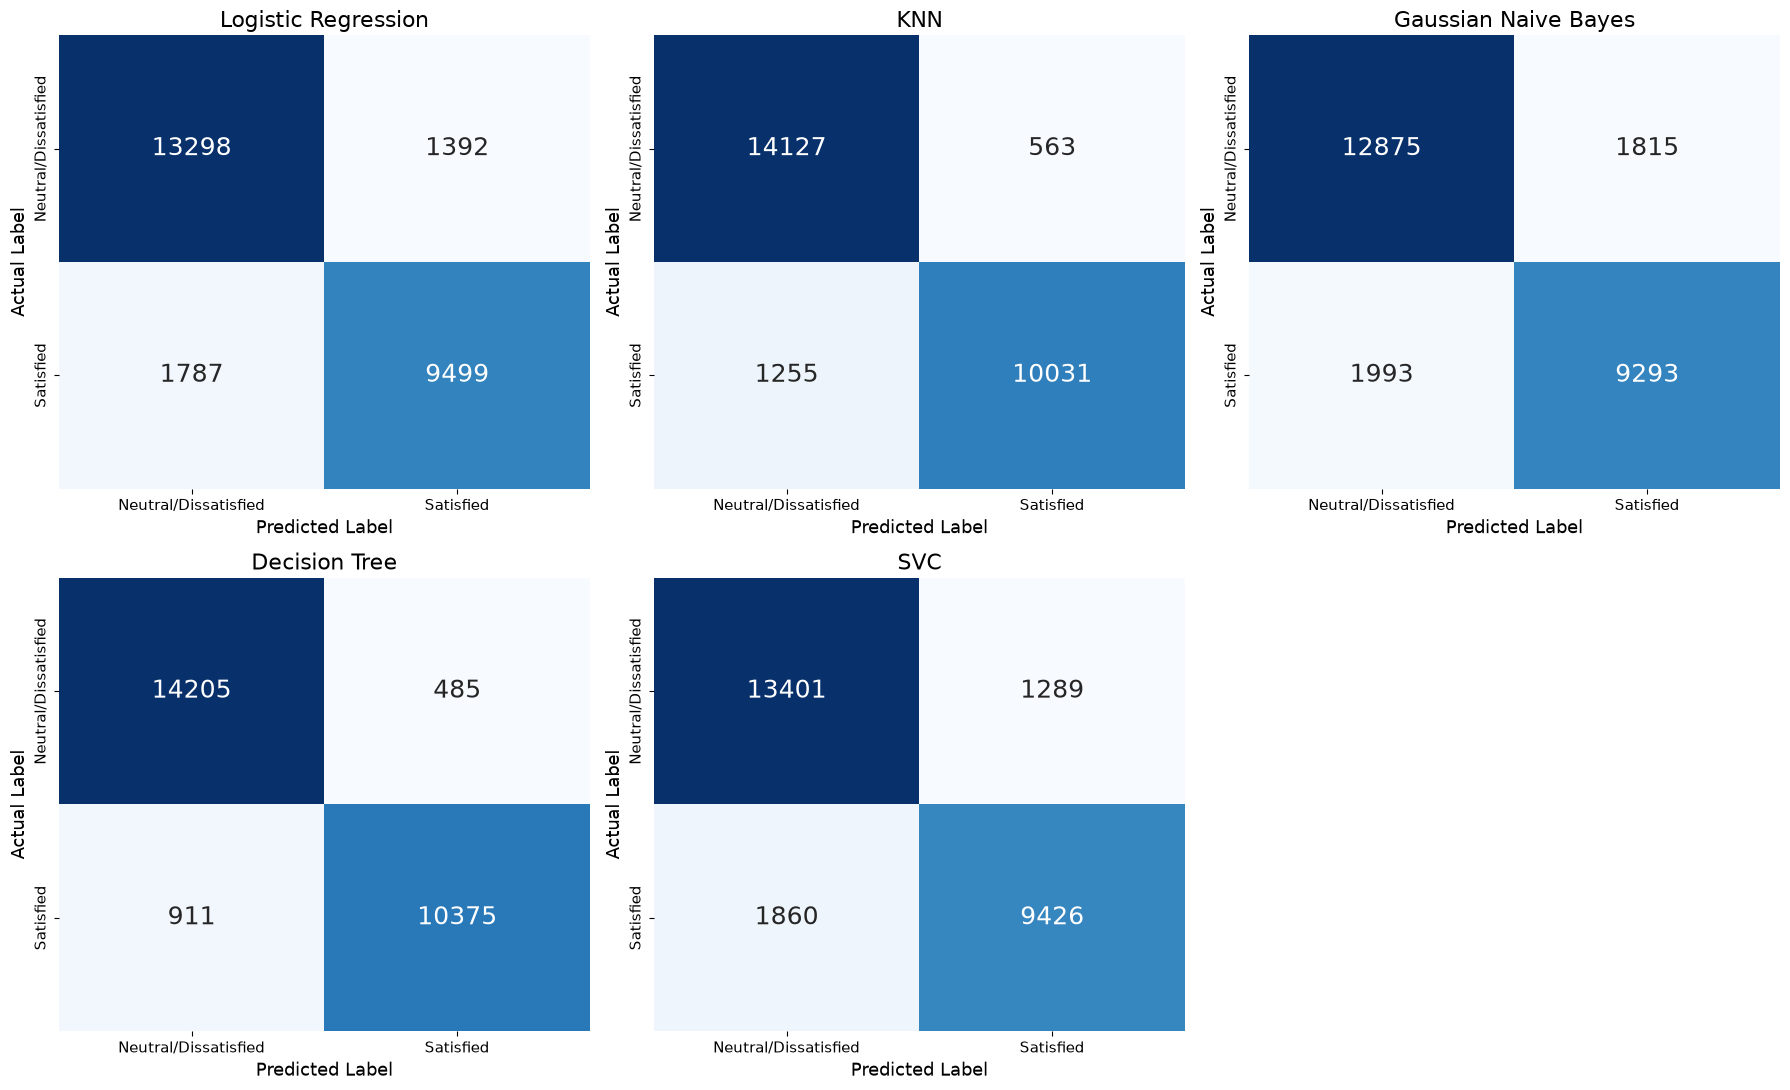

In [13]:
# ============================================================
# D2 (cont.) — PART A CONFUSION MATRICES
# ============================================================

fig, axes = plt.subplots(2, 3, figsize=(18, 11))
axes = axes.flatten()

for ax, (name, preds) in zip(axes, model_predictions.items()):
    cm = confusion_matrix(y_test, preds)
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
        annot_kws={"size": 18},
        xticklabels=["Neutral/Dissatisfied", "Satisfied"],
        yticklabels=["Neutral/Dissatisfied", "Satisfied"]
    )
    ax.set_title(name, fontsize=16)
    ax.set_xlabel("Predicted Label", fontsize=13)
    ax.set_ylabel("Actual Label", fontsize=13)
    ax.tick_params(labelsize=11)


axes[-1].axis("off")

plt.tight_layout()
plt.show()

# Section E — Classification Track, Part B

## E1 — Random Forest, AdaBoost, Gradient Boosting, Bagging and MLP

In this section, the five Part-B classification algorithms are implemented and evaluated using the same training and testing datasets as the Part A classifiers. Hyperparameter tuning is performed for each model to identify suitable configurations. Their performance is compared using accuracy, precision, recall, weighted F1-score and ROC-AUC, with confusion matrices used to examine classification errors. The final consolidated comparison of all ten algorithms is in Section F.

### Step Overview

1. Import the ensemble classifiers and all five evaluation metrics.
2. For each model: train a **baseline**, tune with `RandomizedSearchCV` (training data only), then evaluate the tuned model on the test set.
3. At the end, all ten models are collected into one consolidated table (Section F).

In [14]:
# ============================================================
# E1 — REVIEW 2 CLASSIFICATION IMPORTS
# ============================================================

from sklearn.ensemble import (
    RandomForestClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier
)

from sklearn.model_selection import RandomizedSearchCV

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

from sklearn.pipeline import Pipeline

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [15]:
# ============================================================
# E2 — RANDOM FOREST CLASSIFIER
# ============================================================

# Step 1: Create the baseline Random Forest model

rf_baseline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=1
    ))
])

# Train the baseline model
rf_baseline.fit(X_train, y_train)

# Generate baseline predictions
y_pred_rf_baseline = rf_baseline.predict(X_test)

# Evaluate baseline weighted F1-score
rf_baseline_f1 = f1_score(
    y_test,
    y_pred_rf_baseline,
    average="weighted"
)

print("Baseline Random Forest Weighted F1:", rf_baseline_f1)

Baseline Random Forest Weighted F1: 0.963160570278813


In [16]:
# Step 2: Define the Random Forest pipeline

rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        random_state=42,
        n_jobs=1
    ))
])

# Step 3: Define hyperparameters to test

rf_param_grid = {
    "classifier__n_estimators": [100, 150, 200],
    "classifier__max_depth": [None, 15, 25],
    "classifier__min_samples_split": [2, 5]
}

# Step 4: Perform hyperparameter tuning

rf_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=rf_param_grid,
    n_iter=4,
    scoring="f1_weighted",
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

rf_search.fit(X_train, y_train)

# Step 5: Get the best model

rf_model = rf_search.best_estimator_

print("Best Random Forest Parameters:")
print(rf_search.best_params_)

print("\nBest Cross-Validation Weighted F1:")
print(rf_search.best_score_)

# Step 6: Generate test predictions

y_pred_rf = rf_model.predict(X_test)

print("\nTuned Random Forest Weighted F1:",
      f1_score(y_test, y_pred_rf, average="weighted"))

print("Weighted F1 Improvement:",
      f1_score(y_test, y_pred_rf, average="weighted")
      - rf_baseline_f1)

Fitting 3 folds for each of 4 candidates, totalling 12 fits
Best Random Forest Parameters:
{'classifier__n_estimators': 200, 'classifier__min_samples_split': 5, 'classifier__max_depth': None}

Best Cross-Validation Weighted F1:
0.9616739810845094

Tuned Random Forest Weighted F1: 0.963395664691604
Weighted F1 Improvement: 0.00023509441279101484


Random Forest Evaluation
------------------------
Accuracy: 0.9634662765629812
Precision (weighted): 0.9636649754458302
Recall (weighted): 0.9634662765629812
Weighted F1-score: 0.963395664691604
ROC-AUC: 0.9944710652558814


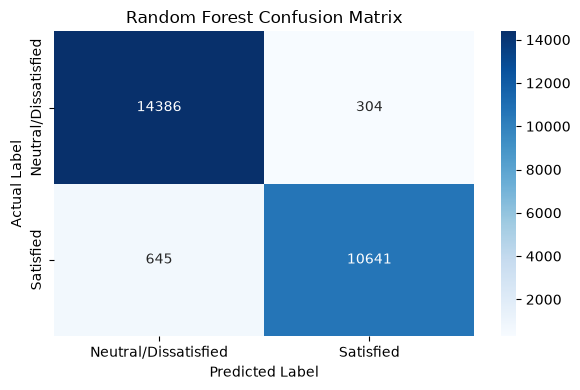

In [17]:
# ============================================================
# E3 — RANDOM FOREST EVALUATION
# ============================================================

rf_accuracy = accuracy_score(y_test, y_pred_rf)

rf_precision = precision_score(
    y_test, y_pred_rf, average="weighted", zero_division=0
)

rf_recall = recall_score(
    y_test, y_pred_rf, average="weighted", zero_division=0
)

rf_f1 = f1_score(
    y_test, y_pred_rf, average="weighted", zero_division=0
)

# ROC-AUC uses the probability of the positive class (Satisfied = 1)
rf_probabilities = rf_model.predict_proba(X_test)[:, 1]

rf_roc_auc = roc_auc_score(y_test, rf_probabilities)

print("Random Forest Evaluation")
print("------------------------")
print("Accuracy:", rf_accuracy)
print("Precision (weighted):", rf_precision)
print("Recall (weighted):", rf_recall)
print("Weighted F1-score:", rf_f1)
print("ROC-AUC:", rf_roc_auc)

# Confusion matrix
rf_cm = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(6, 4))
sns.heatmap(
    rf_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Neutral/Dissatisfied", "Satisfied"],
    yticklabels=["Neutral/Dissatisfied", "Satisfied"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Random Forest Confusion Matrix")
plt.tight_layout()
plt.show()

Top 15 Important Features:


,Feature,Importance
7,numerical__Online Boarding,0.167265
15,numerical__In-flight Wifi Service,0.142243
25,categorical__Class_Business,0.077186
24,categorical__Type of Travel_Personal,0.061239
23,categorical__Type of Travel_Business,0.060081
16,numerical__In-flight Entertainment,0.051729
10,numerical__Seat Comfort,0.045325
5,numerical__Ease of Online Booking,0.039788
26,categorical__Class_Economy,0.035304
11,numerical__Leg Room Service,0.030114


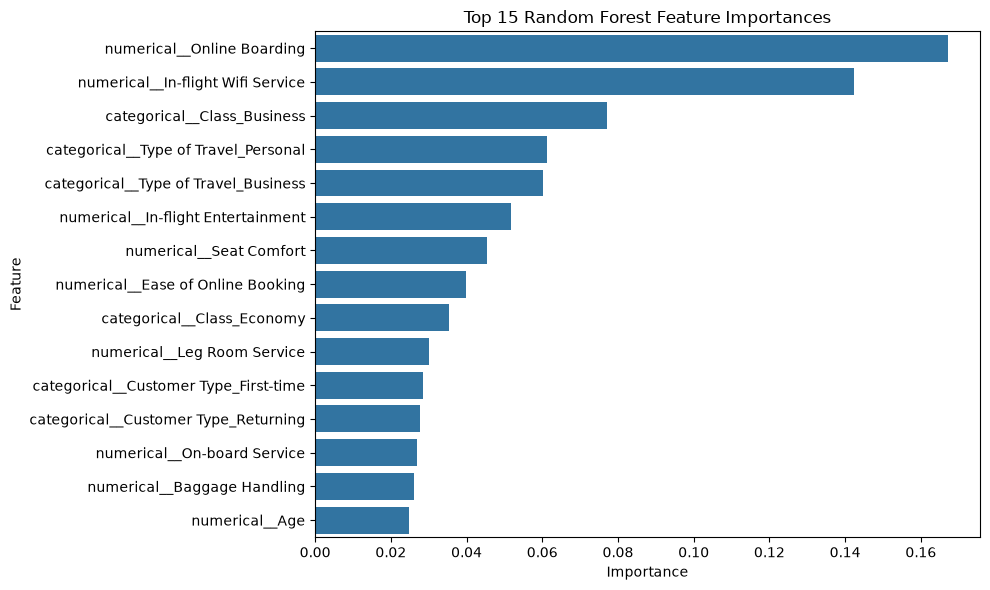

In [18]:
# ============================================================
# E4 — RANDOM FOREST FEATURE IMPORTANCE
# ============================================================

# Get the fitted preprocessor and classifier
rf_preprocessor = rf_model.named_steps["preprocessor"]
rf_classifier = rf_model.named_steps["classifier"]

# Get feature names after encoding
feature_names = rf_preprocessor.get_feature_names_out()

# Create a feature importance table
rf_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_classifier.feature_importances_
})

rf_importance = rf_importance.sort_values(
    by="Importance",
    ascending=False
)

# Display the top 15 features
print("Top 15 Important Features:")
display(rf_importance.head(15))

# Plot feature importance
plt.figure(figsize=(10, 6))

sns.barplot(
    data=rf_importance.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Random Forest Feature Importances")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

## E5 — AdaBoost Classifier

AdaBoost (Adaptive Boosting) is an ensemble learning algorithm that combines multiple weak learners to create a stronger classifier. It gives greater attention to previously misclassified training examples so that subsequent learners can improve the predictions.

In this section, the number of estimators (`n_estimators`) and the learning rate (`learning_rate`) are tuned using cross-validation. The tuned model is evaluated using accuracy, weighted precision, weighted recall, weighted F1-score, ROC-AUC, and a confusion matrix.

### AdaBoost Workflow

Baseline model (E6) → hyperparameter tuning (E7) → test-set evaluation (E8) → confusion matrix (E9).

In [19]:
# ============================================================
# E6 — ADABOOST BASELINE MODEL
# ============================================================

from sklearn.ensemble import AdaBoostClassifier

# Create the AdaBoost pipeline
ada_baseline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", AdaBoostClassifier(
        n_estimators=50,
        learning_rate=1.0,
        random_state=42
    ))
])

# Train the baseline model
ada_baseline.fit(X_train, y_train)

# Generate predictions
y_pred_ada_baseline = ada_baseline.predict(X_test)

# Calculate baseline weighted F1-score
ada_baseline_f1 = f1_score(
    y_test,
    y_pred_ada_baseline,
    average="weighted"
)

print("Baseline AdaBoost Weighted F1:", ada_baseline_f1)

Baseline AdaBoost Weighted F1: 0.9133308024549388


In [20]:
# ============================================================
# E7 — ADABOOST HYPERPARAMETER TUNING
# ============================================================

ada_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", AdaBoostClassifier(
        random_state=42
    ))
])

# Parameters to test
ada_param_grid = {
    "classifier__n_estimators": [50, 100, 150],
    "classifier__learning_rate": [0.5, 1.0, 1.5]
}

# Randomized hyperparameter search
ada_search = RandomizedSearchCV(
    estimator=ada_pipeline,
    param_distributions=ada_param_grid,
    n_iter=4,
    scoring="f1_weighted",
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

# Fit using the training data only
ada_search.fit(X_train, y_train)

# Store the best tuned model
ada_model = ada_search.best_estimator_

print("Best AdaBoost Parameters:")
print(ada_search.best_params_)

print("\nBest Cross-Validation Weighted F1:")
print(ada_search.best_score_)

# Predictions from the tuned model
y_pred_ada = ada_model.predict(X_test)

# Compare baseline and tuned F1-scores
ada_tuned_f1 = f1_score(
    y_test,
    y_pred_ada,
    average="weighted"
)

print("\nBaseline Weighted F1:", ada_baseline_f1)
print("Tuned Weighted F1:", ada_tuned_f1)
print("F1 Improvement:", ada_tuned_f1 - ada_baseline_f1)

Fitting 3 folds for each of 4 candidates, totalling 12 fits
Best AdaBoost Parameters:
{'classifier__n_estimators': 100, 'classifier__learning_rate': 1.5}

Best Cross-Validation Weighted F1:
0.9268912116545427

Baseline Weighted F1: 0.9133308024549388
Tuned Weighted F1: 0.9300361519119331
F1 Improvement: 0.01670534945699431


In [21]:
# ============================================================
# E8 — ADABOOST EVALUATION
# ============================================================

ada_accuracy = accuracy_score(y_test, y_pred_ada)

ada_precision = precision_score(
    y_test, y_pred_ada,
    average="weighted",
    zero_division=0
)

ada_recall = recall_score(
    y_test, y_pred_ada,
    average="weighted",
    zero_division=0
)

ada_f1 = f1_score(
    y_test, y_pred_ada,
    average="weighted",
    zero_division=0
)

# Probability for the positive class: Satisfied = 1
ada_probabilities = ada_model.predict_proba(X_test)[:, 1]

ada_roc_auc = roc_auc_score(
    y_test,
    ada_probabilities
)

print("AdaBoost Evaluation")
print("-------------------")
print("Accuracy:", ada_accuracy)
print("Precision (weighted):", ada_precision)
print("Recall (weighted):", ada_recall)
print("Weighted F1-score:", ada_f1)
print("ROC-AUC:", ada_roc_auc)

AdaBoost Evaluation
-------------------
Accuracy: 0.9300893132121959
Precision (weighted): 0.9300395577364985
Recall (weighted): 0.9300893132121959
Weighted F1-score: 0.9300361519119331
ROC-AUC: 0.978896358519088


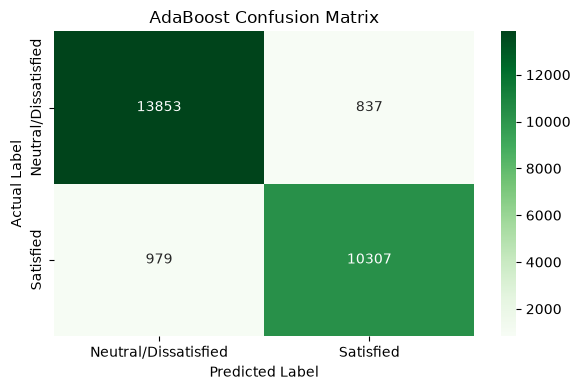

In [22]:
# ============================================================
# E9 — ADABOOST CONFUSION MATRIX
# ============================================================

ada_cm = confusion_matrix(y_test, y_pred_ada)

plt.figure(figsize=(6, 4))

sns.heatmap(
    ada_cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["Neutral/Dissatisfied", "Satisfied"],
    yticklabels=["Neutral/Dissatisfied", "Satisfied"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("AdaBoost Confusion Matrix")
plt.tight_layout()
plt.show()

## E10 — Gradient Boosting Classifier

Gradient Boosting is an ensemble learning algorithm that builds decision trees sequentially. Each new tree attempts to correct errors made by the existing ensemble. The final prediction combines the contributions of the trees.

In this section, the Gradient Boosting Classifier is trained and tuned using cross-validation. Its performance is evaluated using accuracy, weighted precision, weighted recall, weighted F1-score, ROC-AUC, and a confusion matrix.

### Gradient Boosting Workflow

Baseline model (E11) → hyperparameter tuning (E12) → test-set evaluation (E13) → confusion matrix (E14).

In [23]:
# ============================================================
# E11 — GRADIENT BOOSTING BASELINE
# ============================================================

from sklearn.ensemble import GradientBoostingClassifier

gb_baseline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    ))
])

gb_baseline.fit(X_train, y_train)

y_pred_gb_baseline = gb_baseline.predict(X_test)

gb_baseline_f1 = f1_score(
    y_test,
    y_pred_gb_baseline,
    average="weighted"
)

print("Baseline Gradient Boosting Weighted F1:", gb_baseline_f1)

Baseline Gradient Boosting Weighted F1: 0.9430445844979816


In [24]:
# ============================================================
# E12 — GRADIENT BOOSTING HYPERPARAMETER TUNING
# ============================================================

gb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", GradientBoostingClassifier(
        random_state=42
    ))
])

gb_param_grid = {
    "classifier__n_estimators": [100, 150, 200],
    "classifier__learning_rate": [0.05, 0.1, 0.2],
    "classifier__max_depth": [2, 3]
}

gb_search = RandomizedSearchCV(
    estimator=gb_pipeline,
    param_distributions=gb_param_grid,
    n_iter=4,
    scoring="f1_weighted",
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

gb_search.fit(X_train, y_train)

gb_model = gb_search.best_estimator_

print("Best Gradient Boosting Parameters:")
print(gb_search.best_params_)

print("\nBest Cross-Validation Weighted F1:")
print(gb_search.best_score_)

y_pred_gb = gb_model.predict(X_test)

gb_tuned_f1 = f1_score(
    y_test,
    y_pred_gb,
    average="weighted"
)

print("\nBaseline Weighted F1:", gb_baseline_f1)
print("Tuned Weighted F1:", gb_tuned_f1)
print("F1 Improvement:", gb_tuned_f1 - gb_baseline_f1)

Fitting 3 folds for each of 4 candidates, totalling 12 fits
Best Gradient Boosting Parameters:
{'classifier__n_estimators': 200, 'classifier__max_depth': 3, 'classifier__learning_rate': 0.05}

Best Cross-Validation Weighted F1:
0.9412382120005075

Baseline Weighted F1: 0.9430445844979816
Tuned Weighted F1: 0.9435025106643743
F1 Improvement: 0.0004579261663927303


In [25]:
# ============================================================
# E13 — GRADIENT BOOSTING EVALUATION
# ============================================================

gb_accuracy = accuracy_score(y_test, y_pred_gb)

gb_precision = precision_score(
    y_test, y_pred_gb,
    average="weighted",
    zero_division=0
)

gb_recall = recall_score(
    y_test, y_pred_gb,
    average="weighted",
    zero_division=0
)

gb_f1 = f1_score(
    y_test, y_pred_gb,
    average="weighted",
    zero_division=0
)

gb_probabilities = gb_model.predict_proba(X_test)[:, 1]

gb_roc_auc = roc_auc_score(
    y_test,
    gb_probabilities
)

print("Gradient Boosting Evaluation")
print("----------------------------")
print("Accuracy:", gb_accuracy)
print("Precision (weighted):", gb_precision)
print("Recall (weighted):", gb_recall)
print("Weighted F1-score:", gb_f1)
print("ROC-AUC:", gb_roc_auc)

Gradient Boosting Evaluation
----------------------------
Accuracy: 0.943601786264244
Precision (weighted): 0.943683269579282
Recall (weighted): 0.943601786264244
Weighted F1-score: 0.9435025106643743
ROC-AUC: 0.9878691975105575


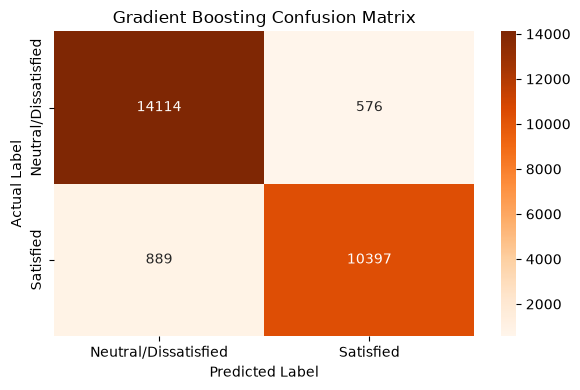

In [26]:
# ============================================================
# E14 — GRADIENT BOOSTING CONFUSION MATRIX
# ============================================================

gb_cm = confusion_matrix(y_test, y_pred_gb)

plt.figure(figsize=(6, 4))

sns.heatmap(
    gb_cm,
    annot=True,
    fmt="d",
    cmap="Oranges",
    xticklabels=["Neutral/Dissatisfied", "Satisfied"],
    yticklabels=["Neutral/Dissatisfied", "Satisfied"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Gradient Boosting Confusion Matrix")
plt.tight_layout()
plt.show()

## E15 — Bagging Classifier

Bagging (Bootstrap Aggregating) is an ensemble learning algorithm that trains many copies of the same base estimator on different bootstrap samples of the training data and combines their predictions by voting. Averaging over many high-variance learners reduces overfitting compared with a single model.

In this section, a Decision Tree is used as the base estimator, as required by the guidelines. The number of estimators (`n_estimators`), the fraction of training samples drawn for each estimator (`max_samples`), and the depth of the base Decision Tree (`max_depth`) are tuned using cross-validation. The tuned model is evaluated using accuracy, weighted precision, weighted recall, weighted F1-score, ROC-AUC, and a confusion matrix.

In [27]:
# ============================================================
# E16 — BAGGING BASELINE MODEL
# ============================================================

from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier

# Create the baseline Bagging pipeline
# A Decision Tree is used as the base estimator
bag_baseline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", BaggingClassifier(
        estimator=DecisionTreeClassifier(random_state=42),
        n_estimators=10,
        random_state=42,
        n_jobs=1
    ))
])

# Train the baseline model
bag_baseline.fit(X_train, y_train)

# Generate baseline predictions
y_pred_bag_baseline = bag_baseline.predict(X_test)

# Calculate baseline weighted F1-score
bag_baseline_f1 = f1_score(
    y_test,
    y_pred_bag_baseline,
    average="weighted"
)

print("Baseline Bagging Weighted F1:", bag_baseline_f1)


Baseline Bagging Weighted F1: 0.9594429613938805


In [28]:
# ============================================================
# E17 — BAGGING HYPERPARAMETER TUNING
# ============================================================

bag_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", BaggingClassifier(
        estimator=DecisionTreeClassifier(random_state=42),
        random_state=42,
        n_jobs=1
    ))
])

# Parameters to test
# estimator__max_depth controls the depth of the base Decision Tree
bag_param_grid = {
    "classifier__n_estimators": [10, 25, 50],
    "classifier__max_samples": [0.5, 0.8, 1.0],
    "classifier__estimator__max_depth": [None, 10]
}

# Randomized hyperparameter search
bag_search = RandomizedSearchCV(
    estimator=bag_pipeline,
    param_distributions=bag_param_grid,
    n_iter=4,
    scoring="f1_weighted",
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

# Fit using the training data only
bag_search.fit(X_train, y_train)

# Store the best tuned model
bag_model = bag_search.best_estimator_

print("Best Bagging Parameters:")
print(bag_search.best_params_)

print("\nBest Cross-Validation Weighted F1:")
print(bag_search.best_score_)

# Predictions from the tuned model
y_pred_bag = bag_model.predict(X_test)

# Compare baseline and tuned F1-scores
bag_tuned_f1 = f1_score(
    y_test,
    y_pred_bag,
    average="weighted"
)

print("\nBaseline Weighted F1:", bag_baseline_f1)
print("Tuned Weighted F1:", bag_tuned_f1)
print("F1 Improvement:", bag_tuned_f1 - bag_baseline_f1)


Fitting 3 folds for each of 4 candidates, totalling 12 fits
Best Bagging Parameters:
{'classifier__n_estimators': 50, 'classifier__max_samples': 0.8, 'classifier__estimator__max_depth': None}

Best Cross-Validation Weighted F1:
0.9600743704043285

Baseline Weighted F1: 0.9594429613938805
Tuned Weighted F1: 0.9631203802036871
F1 Improvement: 0.003677418809806543


In [29]:
# ============================================================
# E18 — BAGGING EVALUATION
# ============================================================

bag_accuracy = accuracy_score(y_test, y_pred_bag)

bag_precision = precision_score(
    y_test, y_pred_bag,
    average="weighted",
    zero_division=0
)

bag_recall = recall_score(
    y_test, y_pred_bag,
    average="weighted",
    zero_division=0
)

bag_f1 = f1_score(
    y_test, y_pred_bag,
    average="weighted",
    zero_division=0
)

# Probability for the positive class: Satisfied = 1
bag_probabilities = bag_model.predict_proba(X_test)[:, 1]

bag_roc_auc = roc_auc_score(
    y_test,
    bag_probabilities
)

print("Bagging Evaluation")
print("------------------")
print("Accuracy:", bag_accuracy)
print("Precision (weighted):", bag_precision)
print("Recall (weighted):", bag_recall)
print("Weighted F1-score:", bag_f1)
print("ROC-AUC:", bag_roc_auc)


Bagging Evaluation
------------------
Accuracy: 0.9631967970434246
Precision (weighted): 0.9634313862529655
Recall (weighted): 0.9631967970434246
Weighted F1-score: 0.9631203802036871
ROC-AUC: 0.9938480562374368


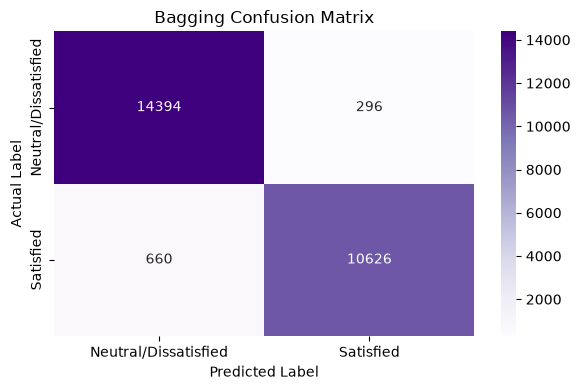

In [30]:
# ============================================================
# E19 — BAGGING CONFUSION MATRIX
# ============================================================

bag_cm = confusion_matrix(y_test, y_pred_bag)

plt.figure(figsize=(6, 4))

sns.heatmap(
    bag_cm,
    annot=True,
    fmt="d",
    cmap="Purples",
    xticklabels=["Neutral/Dissatisfied", "Satisfied"],
    yticklabels=["Neutral/Dissatisfied", "Satisfied"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Bagging Confusion Matrix")
plt.tight_layout()
plt.show()


## E20 — MLP Classifier (Neural Network)

A Multi-Layer Perceptron is a feed-forward neural network trained by back-propagation. It is **sensitive to feature scale**, which is already handled because the shared `preprocessor` standardises the numerical features. `hidden_layer_sizes` (network depth/width) and `activation` (`relu` vs `tanh`) are tuned as required; `alpha` (L2 penalty) is also tuned, and `early_stopping=True` stops training when the validation score stops improving.

Workflow: baseline (E20) → tuning (E21) → evaluation and confusion matrix (E22).

In [31]:
# ============================================================
# E20 — MLP BASELINE
# ============================================================

from sklearn.neural_network import MLPClassifier

mlp_baseline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", MLPClassifier(
        hidden_layer_sizes=(100,),
        activation="relu",
        max_iter=300,
        early_stopping=True,
        random_state=42
    ))
])

mlp_baseline.fit(X_train, y_train)

y_pred_mlp_baseline = mlp_baseline.predict(X_test)

mlp_baseline_f1 = f1_score(y_test, y_pred_mlp_baseline, average="weighted")

print("Baseline MLP Weighted F1:", mlp_baseline_f1)

Baseline MLP Weighted F1: 0.9599520069439342


In [32]:
# ============================================================
# E21 — MLP HYPERPARAMETER TUNING
# ============================================================

mlp_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", MLPClassifier(
        max_iter=300,
        early_stopping=True,
        random_state=42
    ))
])

mlp_param_grid = {
    "classifier__hidden_layer_sizes": [(50,), (100,), (64, 32), (128, 64)],
    "classifier__activation": ["relu", "tanh"],
    "classifier__alpha": [0.0001, 0.001, 0.01]
}

mlp_search = RandomizedSearchCV(
    estimator=mlp_pipeline,
    param_distributions=mlp_param_grid,
    n_iter=6,
    scoring="f1_weighted",
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

# Tune on the training data only
mlp_search.fit(X_train, y_train)

mlp_model = mlp_search.best_estimator_

print("Best MLP Parameters:")
print(mlp_search.best_params_)
print("\nBest Cross-Validation Weighted F1:", mlp_search.best_score_)

y_pred_mlp = mlp_model.predict(X_test)
mlp_tuned_f1 = f1_score(y_test, y_pred_mlp, average="weighted")

print("\nBaseline Weighted F1:", mlp_baseline_f1)
print("Tuned Weighted F1:", mlp_tuned_f1)
print("F1 Improvement:", mlp_tuned_f1 - mlp_baseline_f1)

Fitting 3 folds for each of 6 candidates, totalling 18 fits
Best MLP Parameters:
{'classifier__hidden_layer_sizes': (128, 64), 'classifier__alpha': 0.01, 'classifier__activation': 'relu'}

Best Cross-Validation Weighted F1: 0.9585527430473881

Baseline Weighted F1: 0.9599520069439342
Tuned Weighted F1: 0.9624685522380909
F1 Improvement: 0.00251654529415668


MLP Evaluation
--------------
Accuracy: 0.9625423467816446
Precision (weighted): 0.9627464445908848
Recall (weighted): 0.9625423467816446
Weighted F1-score: 0.9624685522380909
ROC-AUC: 0.9946193269202119


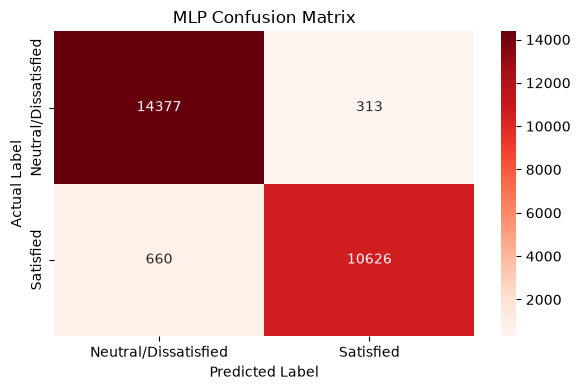

In [33]:
# ============================================================
# E22 — MLP EVALUATION & CONFUSION MATRIX
# ============================================================

mlp_accuracy  = accuracy_score(y_test, y_pred_mlp)
mlp_precision = precision_score(y_test, y_pred_mlp, average="weighted", zero_division=0)
mlp_recall    = recall_score(y_test, y_pred_mlp, average="weighted", zero_division=0)
mlp_f1        = f1_score(y_test, y_pred_mlp, average="weighted", zero_division=0)

mlp_probabilities = mlp_model.predict_proba(X_test)[:, 1]
mlp_roc_auc = roc_auc_score(y_test, mlp_probabilities)

print("MLP Evaluation")
print("--------------")
print("Accuracy:", mlp_accuracy)
print("Precision (weighted):", mlp_precision)
print("Recall (weighted):", mlp_recall)
print("Weighted F1-score:", mlp_f1)
print("ROC-AUC:", mlp_roc_auc)

mlp_cm = confusion_matrix(y_test, y_pred_mlp)

plt.figure(figsize=(6, 4))
sns.heatmap(
    mlp_cm, annot=True, fmt="d", cmap="Reds",
    xticklabels=["Neutral/Dissatisfied", "Satisfied"],
    yticklabels=["Neutral/Dissatisfied", "Satisfied"]
)
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("MLP Confusion Matrix")
plt.tight_layout()
plt.show()

# Section F — Consolidated Comparison & Final Model Selection

This section collects **all ten** classification algorithms (5 from Part A, 5 from Part B) into one table. Every model is evaluated on the **same test split** with the same five metrics: Accuracy, Precision, Recall, F1 (all weighted) and ROC-AUC.

## F1 — Consolidated Comparison Table (all 10 algorithms)

In [34]:
# ============================================================
# F1 — CONSOLIDATED 10-MODEL COMPARISON TABLE
# ============================================================

# Part A models use their default/manual settings; Part B models are the tuned versions
all_models = {
    "Logistic Regression":   logistic_model,
    "KNN":                   knn_model,
    "Gaussian Naive Bayes":  nb_model,
    "Decision Tree":         dt_model,
    "SVC":                   svc_model,
    "Random Forest":         rf_model,
    "AdaBoost":              ada_model,
    "Gradient Boosting":     gb_model,
    "Bagging":               bag_model,
    "MLP":                   mlp_model,
}


def get_scores(model, X):
    """Return a continuous score for the positive class, used for ROC-AUC.
    Uses predict_proba when available, otherwise decision_function (e.g. SVC)."""
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, 1]
    return model.decision_function(X)


def evaluate_model(name, model, X, y):
    """Compute the five required metrics for one fitted model."""
    y_hat = model.predict(X)
    return {
        "Model":     name,
        "Accuracy":  accuracy_score(y, y_hat),
        "Precision": precision_score(y, y_hat, average="weighted", zero_division=0),
        "Recall":    recall_score(y, y_hat, average="weighted", zero_division=0),
        "F1-score":  f1_score(y, y_hat, average="weighted", zero_division=0),
        "ROC-AUC":   roc_auc_score(y, get_scores(model, X)),
    }


final_results = pd.DataFrame(
    [evaluate_model(name, mdl, X_test, y_test) for name, mdl in all_models.items()]
)

# Rank by F1-score (ties broken by ROC-AUC)
final_results = (
    final_results
    .sort_values(by=["F1-score", "ROC-AUC"], ascending=False)
    .reset_index(drop=True)
)
final_results.index = final_results.index + 1   # rank starts at 1
final_results.index.name = "Rank"

print("Consolidated comparison - all 10 classification algorithms (test set)")
display(
    final_results.style
    .format({c: "{:.4f}" for c in ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]})
    .background_gradient(cmap="Blues", subset=["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"])
)

Consolidated comparison - all 10 classification algorithms (test set)


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
Rank,,,,,,
1,Random Forest,0.9635,0.9637,0.9635,0.9634,0.9945
2,Bagging,0.9632,0.9634,0.9632,0.9631,0.9938
3,MLP,0.9625,0.9627,0.9625,0.9625,0.9946
4,Decision Tree,0.9463,0.9465,0.9463,0.9461,0.9862
5,Gradient Boosting,0.9436,0.9437,0.9436,0.9435,0.9879
6,AdaBoost,0.9301,0.9300,0.9301,0.9300,0.9789
7,KNN,0.9300,0.9308,0.9300,0.9297,0.9702
8,SVC,0.8788,0.8788,0.8788,0.8784,0.9307
9,Logistic Regression,0.8776,0.8775,0.8776,0.8773,0.9303


### F1 — Observation

- **Best overall:** Random Forest ranks first on every metric (Accuracy 0.9635, Precision 0.9637, Recall 0.9635, F1 0.9634, ROC-AUC 0.9945). Bagging (F1 0.9631) and MLP (F1 0.9625) are very close behind, so the top three differ by less than 0.001 in F1.
- **Part B vs Part A:** The Part-B models (Random Forest, Bagging, MLP) clearly outperform the simpler Part-A models. The best Part-A model, Decision Tree (F1 0.9461), is about 0.017 below Random Forest. Gradient Boosting (0.9435) is slightly below Decision Tree, and AdaBoost (0.9300) is below it too.
- **ROC-AUC:** MLP has the highest ROC-AUC (0.9946), marginally above Random Forest (0.9945), but the gap is negligible. Both Random Forest and Bagging are above 0.99, which means they separate satisfied and dissatisfied passengers very well across all thresholds.
- **Weakest models:** Gaussian Naive Bayes (F1 0.8533), Logistic Regression (0.8773) and SVC with a linear kernel (0.8784) perform worst, with ROC-AUC around 0.92 to 0.93. Logistic Regression and the linear SVC can only draw a straight decision boundary, and Naive Bayes assumes the features are independent. The service-rating features are probably correlated and interact with each other, so both assumptions fit poorly. The ROC curves show the same split: tree-based models and the MLP sit clearly above the linear and probabilistic models.
- **Class balance:** Precision and recall are almost identical to accuracy for every model. This is because the weighted averages are dominated by the two classes, which are only moderately imbalanced (about 56% vs 44%), so accuracy is a reliable metric here.

## F2 — Hyperparameter Tuning Summary (baseline vs tuned)

In [35]:
# ============================================================
# F2 — TUNING SUMMARY: BASELINE vs TUNED (weighted F1)
# ============================================================

tuning_summary = pd.DataFrame([
    {"Model": "Random Forest",     "Baseline F1": rf_baseline_f1,  "Tuned F1": rf_f1,  "Best Parameters": rf_search.best_params_},
    {"Model": "AdaBoost",          "Baseline F1": ada_baseline_f1, "Tuned F1": ada_f1, "Best Parameters": ada_search.best_params_},
    {"Model": "Gradient Boosting", "Baseline F1": gb_baseline_f1,  "Tuned F1": gb_f1,  "Best Parameters": gb_search.best_params_},
    {"Model": "Bagging",           "Baseline F1": bag_baseline_f1, "Tuned F1": bag_f1, "Best Parameters": bag_search.best_params_},
    {"Model": "MLP",               "Baseline F1": mlp_baseline_f1, "Tuned F1": mlp_f1, "Best Parameters": mlp_search.best_params_},
])

tuning_summary["F1 Improvement"] = tuning_summary["Tuned F1"] - tuning_summary["Baseline F1"]

pd.set_option("display.max_colwidth", None)
display(tuning_summary.style.format({
    "Baseline F1": "{:.4f}", "Tuned F1": "{:.4f}", "F1 Improvement": "{:+.4f}"
}))

,Model,Baseline F1,Tuned F1,Best Parameters,F1 Improvement
0,Random Forest,0.9632,0.9634,"{'classifier__n_estimators': 200, 'classifier__min_samples_split': 5, 'classifier__max_depth': None}",+0.0002
1,AdaBoost,0.9133,0.9300,"{'classifier__n_estimators': 100, 'classifier__learning_rate': 1.5}",+0.0167
2,Gradient Boosting,0.9430,0.9435,"{'classifier__n_estimators': 200, 'classifier__max_depth': 3, 'classifier__learning_rate': 0.05}",+0.0005
3,Bagging,0.9594,0.9631,"{'classifier__n_estimators': 50, 'classifier__max_samples': 0.8, 'classifier__estimator__max_depth': None}",+0.0037
4,MLP,0.9600,0.9625,"{'classifier__hidden_layer_sizes': (128, 64), 'classifier__alpha': 0.01, 'classifier__activation': 'relu'}",+0.0025


### F2 — Observation

- **Largest gain:** AdaBoost improved the most from tuning, with weighted F1 rising from 0.9133 to 0.9300 (+0.0167). Its best learning rate (1.5) is at the edge of the search grid, so a wider grid might improve it further.
- **Moderate gains:** Bagging (+0.0037, 0.9594 to 0.9631) and MLP (+0.0025, 0.9600 to 0.9625) improved slightly. For Bagging, 50 estimators with `max_samples = 0.8` worked best. For MLP, a larger network (128, 64) with `alpha = 0.01` worked best.
- **Almost no gain:** Random Forest (+0.0002) and Gradient Boosting (+0.0005) barely changed. Their default settings were already close to optimal on this dataset (about 104,000 training rows), so tuning had little room to help.
- **Takeaway:** Tuning helps most for models whose defaults are weak (AdaBoost), while bagging-based models are already strong at their defaults. After tuning, the ranking of the top models did not change materially, so the choice of algorithm matters more than the choice of hyperparameters here.

## F3 — Cross-Validation of the Two Best Models

The guidelines require cross-validation for at least the two best-performing models. 5-fold stratified CV on the **training set** is used, so the test set stays untouched.

In [36]:
# ============================================================
# F3 — 5-FOLD CROSS-VALIDATION FOR THE TOP-2 MODELS
# ============================================================

from sklearn.model_selection import cross_val_score, StratifiedKFold

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

top2_names = final_results["Model"].head(2).tolist()

cv_rows = []
for name in top2_names:
    scores = cross_val_score(
        all_models[name], X_train, y_train,
        cv=skf, scoring="f1_weighted", n_jobs=1
    )
    cv_rows.append({
        "Model": name,
        "CV Mean F1": scores.mean(),
        "CV Std": scores.std(),
        "Fold Scores": [round(s, 4) for s in scores],
    })

cv_table = pd.DataFrame(cv_rows)
display(cv_table.style.format({"CV Mean F1": "{:.4f}", "CV Std": "{:.4f}"}))

,Model,CV Mean F1,CV Std,Fold Scores
0,Random Forest,0.9620,0.0006,"[np.float64(0.9616), np.float64(0.9628), np.float64(0.9625), np.float64(0.9619), np.float64(0.9614)]"
1,Bagging,0.9612,0.0007,"[np.float64(0.9609), np.float64(0.9625), np.float64(0.9615), np.float64(0.9609), np.float64(0.9604)]"


## F4 — ROC Curves (all 10 models)

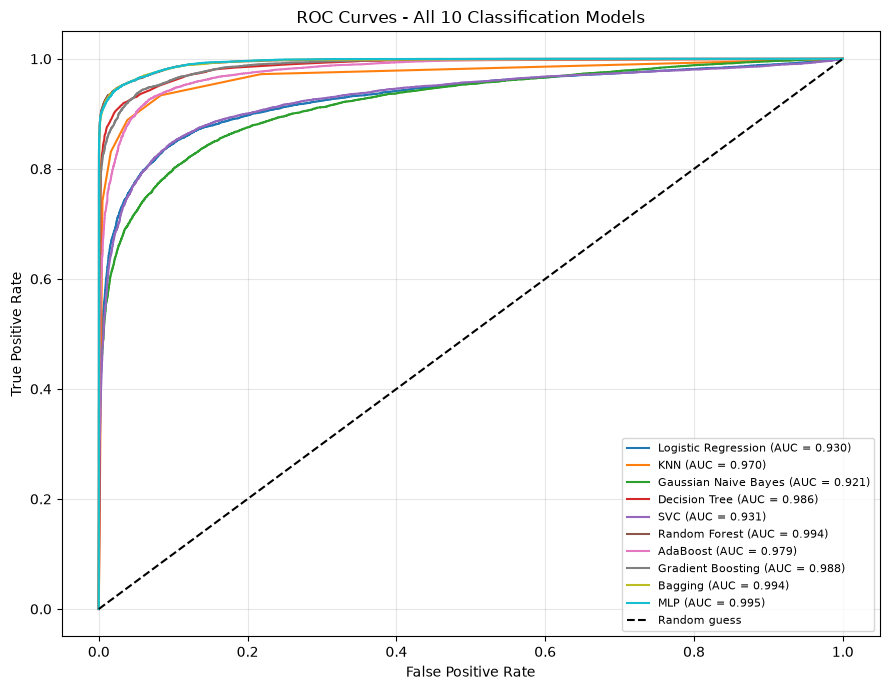

In [37]:
# ============================================================
# F4 — ROC CURVES FOR ALL 10 MODELS
# ============================================================

from sklearn.metrics import roc_curve

plt.figure(figsize=(9, 7))
colors = sns.color_palette("tab10", n_colors=len(all_models))   # colourblind-friendly palette

for (name, mdl), color in zip(all_models.items(), colors):
    fpr, tpr, _ = roc_curve(y_test, get_scores(mdl, X_test))
    auc_value = final_results.loc[final_results["Model"] == name, "ROC-AUC"].iloc[0]
    plt.plot(fpr, tpr, color=color, label=f"{name} (AUC = {auc_value:.3f})")

plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves - All 10 Classification Models")
plt.legend(loc="lower right", fontsize=8)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## F5 — Final Model Selection

In [38]:
# ============================================================
# F5 — FINAL MODEL: CLASSIFICATION REPORT & SAVE
# ============================================================

import os, joblib

best_name  = final_results.loc[1, "Model"]       # rank 1 by weighted F1
best_model = all_models[best_name]

print("Selected final model:", best_name)
print()
print(classification_report(
    y_test, best_model.predict(X_test),
    target_names=["Neutral/Dissatisfied", "Satisfied"]
))

# Save the final model (repo structure: models/best_model.pkl)
os.makedirs("../models", exist_ok=True)
joblib.dump(best_model, "../models/best_model.pkl")
print("Model saved to ../models/best_model.pkl")

Selected final model: Random Forest

                      precision    recall  f1-score   support

Neutral/Dissatisfied       0.96      0.98      0.97     14690
           Satisfied       0.97      0.94      0.96     11286

            accuracy                           0.96     25976
           macro avg       0.96      0.96      0.96     25976
        weighted avg       0.96      0.96      0.96     25976

Model saved to ../models/best_model.pkl


### Final Model Selection — Justification

**Selected model: Random Forest Classifier** (tuned: `n_estimators = 200`, `min_samples_split = 5`, `max_depth = None`)

**Why this model:**
- **Performance:** Random Forest ranks first among all 10 algorithms on the held-out test set: Accuracy 0.9635, Precision 0.9637, Recall 0.9635, weighted F1 0.9634 and ROC-AUC 0.9945. It beats the best Part-A model (Decision Tree, F1 0.9461) by about 0.017 F1.
- **Stability:** 5-fold stratified cross-validation on the training set gives a mean weighted F1 of 0.9620 with a standard deviation of only 0.0006 (fold scores 0.9614 to 0.9628). This is very close to the test F1 of 0.9634, so the model generalises well and is not overfitting to a lucky split.
- **Hyperparameter tuning:** `RandomizedSearchCV` (3-fold, scored on weighted F1) was applied to all five Part-B models. For Random Forest, weighted F1 improved from 0.9632 (baseline) to 0.9634 (tuned), a small improvement of +0.0002. Larger improvements were seen for AdaBoost (+0.0167) and Bagging (+0.0037), as documented in F2.
- **Error analysis:** The classification report shows recall of 0.98 for Neutral/Dissatisfied and 0.94 for Satisfied. The model therefore rarely labels a dissatisfied passenger as satisfied (about [FP count from the RF confusion matrix] cases), and its more common error is labelling a satisfied passenger as dissatisfied (about [FN count] cases). For an airline, missing a dissatisfied passenger is usually the costlier error, because those customers are the ones at risk of churn, so this error pattern is favourable.
- **Interpretability:** Random Forest provides feature importances (E4), which show which service factors drive satisfaction and give the airline actionable information.

**Why not Bagging or MLP?** Bagging (F1 0.9631) and MLP (F1 0.9625) are practically tied with Random Forest, since the differences are comparable to the cross-validation standard deviation. MLP has a marginally higher ROC-AUC (0.9946 vs 0.9945), but Random Forest is slightly better on all four threshold-based metrics, has lower variance across folds, and is easier to interpret than a neural network.

**Trade-offs:** Random Forest with 200 trees is slower to train and larger to store than a single Decision Tree or Logistic Regression, and it is less transparent than those simpler models. Given the large accuracy gain (about 0.09 F1 over Logistic Regression), this cost is justified for this problem.